In [1]:
import zipfile
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

Part A - How many clusters? Elbow and silhouette

In [2]:
customers = pd.read_csv(DATA / "mall_customers_dataset.csv")
print(customers.head())

features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = StandardScaler().fit_transform(customers[features])

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


k=2 inertia=389.4 silhouette=0.335
k=3 inertia=295.2 silhouette=0.358
k=4 inertia=205.2 silhouette=0.404
k=5 inertia=168.2 silhouette=0.417
k=6 inertia=133.9 silhouette=0.427
k=7 inertia=117.0 silhouette=0.417
k=8 inertia=103.8 silhouette=0.409


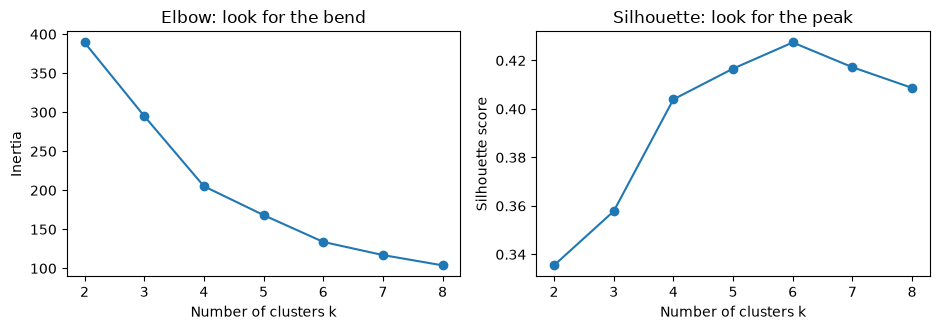

In [3]:
ks, inertias, silhouettes = [], [], []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = kmeans.fit_predict(X)
    ks.append(k)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X, labels))
    print(f"k={k} inertia={kmeans.inertia_:.1f} silhouette={silhouettes[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow: look for the bend")
axes[1].plot(ks, silhouettes, marker="o")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette: look for the peak")
plt.tight_layout()
plt.show()

Part B - K-means versus DBSCAN

In [5]:
kmeans = KMeans(n_clusters=5, n_init=30, random_state=42)
k_labels = kmeans.fit_predict(X)
print("K-means silhouette:", round(silhouette_score(X, k_labels), 3))

dbscan = DBSCAN(eps=0.75, min_samples=6)
d_labels = dbscan.fit_predict(X)
is_clustered = d_labels != -1
n_clusters = len(set(d_labels[is_clustered]))
print("DBSCAN clusters:", n_clusters, "noise points:", int((~is_clustered).sum()))
if n_clusters >= 2:
    print("DBSCAN silhouette (clustered points only):",
          round(silhouette_score(X[is_clustered], d_labels[is_clustered]), 3))


K-means silhouette: 0.417
DBSCAN clusters: 1 noise points: 14


In [6]:
segments = customers.copy()
segments["kmeans_cluster"] = k_labels
segments["dbscan_cluster"] = d_labels
profile = segments.groupby("kmeans_cluster")[features].mean().round(1)
profile["customers"] = segments["kmeans_cluster"].value_counts().sort_index()
print(profile)

                 Age  Annual Income (k$)  Spending Score (1-100)  customers
kmeans_cluster                                                             
0               46.2                26.8                    18.4         20
1               25.2                41.1                    62.2         54
2               32.9                86.1                    81.5         40
3               39.9                86.1                    19.4         39
4               55.6                54.4                    48.9         47


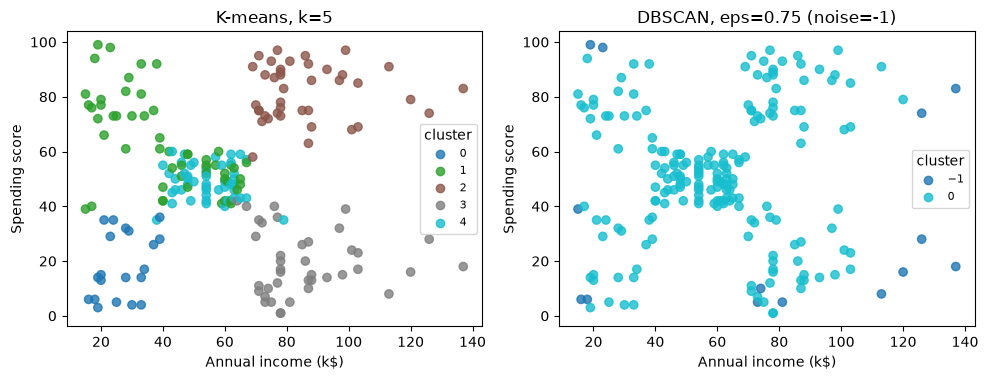

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
panels = [(axes[0], k_labels, "K-means, k=5"),
          (axes[1], d_labels, "DBSCAN, eps=0.75 (noise=-1)")]
for ax, labels, title in panels:
    scatter = ax.scatter(customers["Annual Income (k$)"], customers["Spending Score (1-100)"],
                         c=labels, cmap="tab10", alpha=0.8)
    ax.set_xlabel("Annual income (k$)")
    ax.set_ylabel("Spending score")
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="cluster", fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

Part C - PCA as compression, judged by a downstream model

training digits: 3823 test digits: 1797


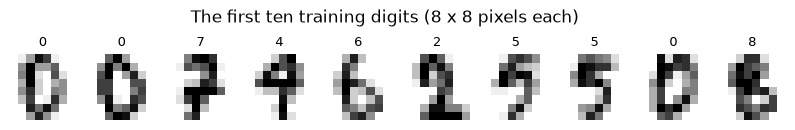

In [8]:
archive_path = DATA / "optical_recognition_handwritten_digits.zip"
columns = [f"pixel_{i}" for i in range(64)] + ["label"]
with zipfile.ZipFile(archive_path) as archive:
    members = {Path(name).name: name for name in archive.namelist()}
    train = pd.read_csv(archive.open(members["optdigits.tra"]), header=None, names=columns)
    test = pd.read_csv(archive.open(members["optdigits.tes"]), header=None, names=columns)

X_dev = train.drop(columns="label") / 16.0
y_dev = train["label"]
X_test = test.drop(columns="label") / 16.0
y_test = test["label"]

print("training digits:", len(X_dev), "test digits:", len(X_test))

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, (_, row), label in zip(axes, X_dev.head(10).iterrows(), y_dev.head(10)):
    ax.imshow(row.to_numpy().reshape(8, 8), cmap="gray_r")
    ax.set_title(str(label), fontsize=9)
    ax.axis("off")
plt.suptitle("The first ten training digits (8 x 8 pixels each)", y=1.05)
plt.show()

In [9]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)

baseline = LogisticRegression(max_iter=2000).fit(X_fit, y_fit)
print("all 64 pixels: validation accuracy =",
      round(accuracy_score(y_valid, baseline.predict(X_valid)), 4))

for retained_variance in [0.90, 0.95, 0.99]:
    candidate = Pipeline([
        ("pca", PCA(n_components=retained_variance, svd_solver="full")),
        ("model", LogisticRegression(max_iter=2000)),
    ])
    candidate.fit(X_fit, y_fit)
    n_kept = candidate.named_steps["pca"].n_components_
    print(f"{retained_variance:.0%} variance: {n_kept:2d} components, "
          f"validation accuracy = {accuracy_score(y_valid, candidate.predict(X_valid)):.4f}")

all 64 pixels: validation accuracy = 0.955
90% variance: 21 components, validation accuracy = 0.9487
95% variance: 29 components, validation accuracy = 0.9540
99% variance: 41 components, validation accuracy = 0.9561


In [10]:
final_model = Pipeline([
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("model", LogisticRegression(max_iter=2000)),
])
final_model.fit(X_dev, y_dev)

full_model = LogisticRegression(max_iter=2000).fit(X_dev, y_dev)
pca = final_model.named_steps["pca"]

print("\nFINAL TEST (official test file)")
print("all 64 pixels accuracy:", round(accuracy_score(y_test, full_model.predict(X_test)), 4))
print("PCA components kept:", pca.n_components_,
      "variance retained:", round(pca.explained_variance_ratio_.sum(), 4))
print("PCA -> logistic accuracy:", round(accuracy_score(y_test, final_model.predict(X_test)), 4))


FINAL TEST (official test file)
all 64 pixels accuracy: 0.9477
PCA components kept: 29 variance retained: 0.9537
PCA -> logistic accuracy: 0.9477


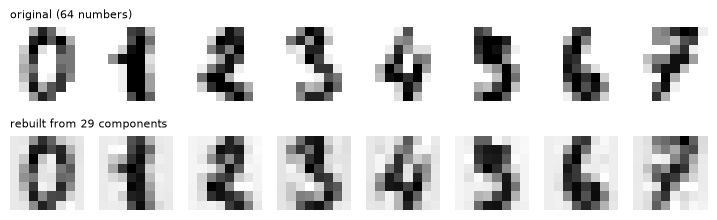

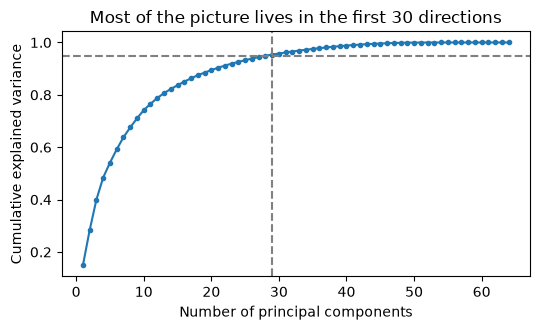

In [11]:
reconstructed = pca.inverse_transform(pca.transform(X_test.head(8)))

fig, axes = plt.subplots(2, 8, figsize=(9, 2.6))
for j in range(8):
    axes[0, j].imshow(X_test.iloc[j].to_numpy().reshape(8, 8), cmap="gray_r")
    axes[1, j].imshow(reconstructed[j].reshape(8, 8), cmap="gray_r")
    axes[0, j].axis("off")
    axes[1, j].axis("off")
axes[0, 0].set_title("original (64 numbers)", fontsize=8, loc="left")
axes[1, 0].set_title(f"rebuilt from {pca.n_components_} components", fontsize=8, loc="left")
plt.show()

plt.figure(figsize=(5.5, 3.4))
all_components = PCA(svd_solver="full").fit(X_dev)
plt.plot(np.arange(1, 65), np.cumsum(all_components.explained_variance_ratio_), marker=".")
plt.axhline(0.95, linestyle="--", color="grey")
plt.axvline(pca.n_components_, linestyle="--", color="grey")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Most of the picture lives in the first 30 directions")
plt.tight_layout()
plt.show()

In [12]:
model_path = MODELS / "digits_pca_logistic.joblib"
joblib.dump(final_model, model_path)

loaded = joblib.load(model_path)
first_digits = X_test.iloc[:5]
print("predicted:", loaded.predict(first_digits).tolist())
print("actual:   ", y_test.iloc[:5].tolist())

predicted: [0, 1, 1, 3, 4]
actual:    [0, 1, 2, 3, 4]


Try it yourself: DBSCAN with eps = 0.5

In [14]:
dbscan_05 = DBSCAN(eps=0.5, min_samples=6)
d_labels_05 = dbscan_05.fit_predict(X)

is_clustered_05 = d_labels_05 != -1
n_clusters_05 = len(set(d_labels_05[is_clustered_05]))
n_noise_05 = int((~is_clustered_05).sum())

print(f"DBSCAN (eps=0.5) clusters: {n_clusters_05}, noise points: {n_noise_05}")
if n_clusters_05 >= 2:
    print("DBSCAN silhouette (clustered points):", 
          round(silhouette_score(X[is_clustered_05], d_labels_05[is_clustered_05]), 3))

DBSCAN (eps=0.5) clusters: 5, noise points: 66
DBSCAN silhouette (clustered points): 0.528


Marketing Justification

Observed Outcome: Dropping eps from 0.75 down to 0.5 causes DBSCAN to mark a significantly higher number of customers as noise (label -1) because points now require a much tighter neighborhood radius to form or join a density cluster.


Which result better serves marketing?

K-means ($k=5$): Better for general customer segmentation. It cleanly partitions all 200 customers into 5 distinct groups (e.g., High Income / High Spending, Low Income / High Spending). This allows the marketing team to assign every customer to a tailored promotional strategy or campaign segment.

DBSCAN ($eps=0.5$): Better for finding core target audiences or fraud/anomaly detection. Because DBSCAN leaves outliers and low-density region points unassigned, it identifies only highly dense, core customer behaviors. While less useful for broad marketing campaigns (since many customers are ignored as "noise"), it is superior if marketing wants to target only tightly grouped customer niches or filter out unusual consumer behaviors.

Check Your Understanding

1. What does PCA optimize when it chooses its first principal component?

The first principal component is chosen along the direction in the feature space that maximizes the variance of the projected data points. Equivalently, this direction minimizes the reconstruction error (the mean squared Euclidean distance between the original data points and their projections onto that principal axis).


2. Why can standardization change which PCA directions appear most important?

PCA is sensitive to the variance scale of the features. If features are measured on vastly different scales (for example, Annual Income ranging from $15\text{–}137$ versus Spending Score ranging from $1\text{–}100$), an unscaled feature with larger numerical values will artificially dominate the overall variance.

Standardizing features ensures each variable contributes equally (mean of $0$, variance of $1$), allowing PCA to identify principal components based on true linear relationships and covariance structure rather than measurement units or scale magnitudes.

3. Why should distances and apparent cluster sizes in a t-SNE or UMAP plot not be interpreted as exact properties of the original high-dimensional data?

t-SNE and UMAP are non-linear dimensionality reduction techniques designed primarily for visualization, not metric preservation. They prioritize local neighborhood relationships (keeping close points together) at the expense of global geometry:

- Inter-cluster distances: The distance between separate clusters on a 2D t-SNE or UMAP plot does not reflect their actual distance in the original high-dimensional space.
- Cluster sizes and density: The apparent size, spread, or density of a cluster on the plot is heavily influenced by hyperparameter choices (such as perplexity in t-SNE or n_neighbors in UMAP) rather than the true underlying variance in high dimensions.